# Split Labeled Diagnostic Data (Step 2)

In [35]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from dotenv import load_dotenv

In [36]:
load_dotenv()

X_path = os.getenv("SPLIT_LABELED_DIAGNOSTIC_X_CSV_PATH")
y_path = os.getenv("SPLIT_LABELED_DIAGNOSTIC_Y_TSV_PATH")
output_dir = os.getenv("SPLIT_OUTPUT_DIR")
random_seed = int(os.getenv("RANDOM_SEED"))

# Fraction of the data to use for training (default: 0.70).
# The remaining data will be split equally into calibration and test."""
train_frac = float(os.getenv("SPLIT_TRAIN_FRAC", 0.7))

# Minimum number of samples per class that must be available to further split into
# calibration and test sets. Classes not reaching this threshold will be excluded
# from the calibration set (default: 10).
min_calibration_samples = int(os.getenv("SPLIT_MIN_CALIBRATION_SAMPLES", 10))

print("Configuration:")
print(f"X path: {X_path}")
print(f"y path: {y_path}")
print(f"Output dir: {output_dir}")
print(f"Random seed: {random_seed}")
print(f"Train frac: {train_frac}")
print(f"Min calibration samples: {min_calibration_samples}")


Configuration:
X path: /home/mariya/Data/pallas/training/pallas.labeled_diagnostic.X.csv
y path: /home/mariya/Data/pallas/training/pallas.labeled_diagnostic.y.tsv
Output dir: /home/mariya/Data/pallas/training
Random seed: 3232
Train frac: 0.7
Min calibration samples: 10


In [37]:
# Make sure output dir exists
os.makedirs(output_dir, exist_ok=True)

def plot_class_distribution(y_series, title):
    counts = y_series.value_counts().sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    counts.plot(kind='bar')
    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.xticks(rotation=90)
    plt.show()

# Function to save data
def save_data_split(X, y, prefix):
    X.to_csv(f'{output_dir}/pallas.split.labeled_diagnostic.{prefix}.X.csv')
    y.to_csv(f'{output_dir}/pallas.split.labeled_diagnostic.{prefix}.y.tsv', sep='\t')
    plot_class_distribution(y, f'Class Distribution for {prefix} Split')

In [38]:
X = pd.read_csv(X_path, header=0, index_col=0)
X

,ENSG00000000003,ENSG00000000005,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,...,ENSG00000293642,ENSG00000293661,ENSG00000293662,ENSG00000293663,ENSG00000293685,ENSG00000293689,ENSG00000293691,ENSG00000300510,ENSG00000310517,ENSG00000310525
id,,,,,,,,,,,,,,,,,,,,,
16-001,-1.030936,-1.324478,4.107419,4.481528,5.313913,4.318306,-0.006233,0.682168,4.419238,6.533335,...,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478
16-002,-0.683009,-1.324478,4.564085,2.704030,4.879351,3.515584,-0.048009,2.102919,3.897675,6.750946,...,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478
16-003,-0.795420,-1.324478,4.001798,4.804804,5.278272,2.338792,-0.009478,1.674171,4.069893,6.442101,...,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478
16-006,-0.976469,-1.324478,4.335444,4.571098,4.364741,3.808390,-1.051959,1.764196,3.514185,6.925137,...,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478
16-008,3.986329,-1.324478,4.179535,5.059009,4.009802,5.316485,-0.391770,2.303854,5.361421,7.219616,...,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SJTALL169_D,-1.324478,-1.324478,5.020547,3.936178,3.989832,4.000849,2.358342,5.997673,6.300551,5.633695,...,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478
SJTALL174_D,-1.096536,-1.324478,3.893166,4.396042,4.976536,5.103507,5.563309,4.615500,4.329157,7.725124,...,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478
SJTALL182_D,-1.324478,-1.324478,3.926871,4.020709,6.216572,4.546595,2.511116,4.795256,5.371875,6.776146,...,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478,-1.324478


In [39]:
y = pd.read_csv(y_path, header=0, index_col=0, sep="\t")
y = y['y']
y

id
16-001         Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1
16-002         Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1
16-003         Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1
16-006         Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1
16-008                                       Disease,T-ALL
                                  ...                     
SJTALL169_D                                  Disease,T-ALL
SJTALL174_D                                  Disease,T-ALL
SJTALL182_D                                  Disease,T-ALL
SJTALL186_D                                  Disease,T-ALL
SJTALL187_D                                  Disease,T-ALL
Name: y, Length: 3191, dtype: object

In [40]:
# Assert that they are the same length
assert len(X) == len(y), f"X and y have different lengths: {len(X)} vs {len(y)}"

In [41]:
X_train, X_rest, y_train, y_rest = train_test_split(
        X,
        y,
        train_size=train_frac,
        random_state=random_seed,
        stratify=y)

# Print shape of each
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_rest shape: {X_rest.shape}")
print(f"y_rest shape: {y_rest.shape}")

X_train shape: (2233, 19916)
y_train shape: (2233,)
X_rest shape: (958, 19916)
y_rest shape: (958,)


In [42]:
# In the rest split, remove samples totaling less
# than the calibration sample minimum.
# Put them into a separate data split.
low_class_indices = y_rest.isin(
    y_rest.value_counts()[
        y_rest.value_counts() < min_calibration_samples].index
)
X_low, y_low = X_rest[low_class_indices], y_rest[low_class_indices]
X_rest = X_rest[~X_rest.index.isin(X_low.index)]
y_rest = y_rest[~y_rest.index.isin(y_low.index)]

# Print all classes in this split and the number of samples in each
print("The following classes will be excluded from the calibration set:")
for class_label in y_low.unique():
    class_count = y_low.value_counts().get(class_label, 0)
    print(f" - Class {class_label}: {class_count} samples")

# Print shape of each
print(f"X_low shape: {X_low.shape}")
print(f"y_low shape: {y_low.shape}")
print(f"X_rest shape: {X_rest.shape}")
print(f"y_rest shape: {y_rest.shape}")

The following classes will be excluded from the calibration set:
 - Class Disease,B-ALL,MYC-r: 5 samples
 - Class Disease,B-ALL,NUTM1-r: 6 samples
 - Class Disease,AML,NPM1alt: 8 samples
 - Class Disease,AML,DEK::NUP214: 2 samples
 - Class Disease,AML,APL-PML::RARA: 1 samples
 - Class Disease,Non-leukemic: 4 samples
 - Class Disease,AML,NUP98-r: 6 samples
 - Class Disease,AML,CBFA2T3::GLIS2: 2 samples
 - Class Disease,AML,BCR::ABL1: 3 samples
 - Class Disease,B-ALL,HLF-r: 3 samples
 - Class Disease,AML,CEBPAalt: 4 samples
 - Class Disease,B-ALL,IKZF1 N159Y: 2 samples
X_low shape: (46, 19916)
y_low shape: (46,)
X_rest shape: (912, 19916)
y_rest shape: (912,)


In [43]:
# Split remaining data 50/50
X_calib, X_test, y_calib, y_test = train_test_split(
    X_rest,
    y_rest,
    test_size=0.5,
    random_state=random_seed,
    stratify=y_rest
)

# Print shape of each
print(f"X_calib shape: {X_calib.shape}")
print(f"y_calib shape: {y_calib.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_calib shape: (456, 19916)
y_calib shape: (456,)
X_test shape: (456, 19916)
y_test shape: (456,)


In [44]:
# Merge low items into test set
X_test = pd.concat([X_test, X_low])
y_test = pd.concat([y_test, y_low])

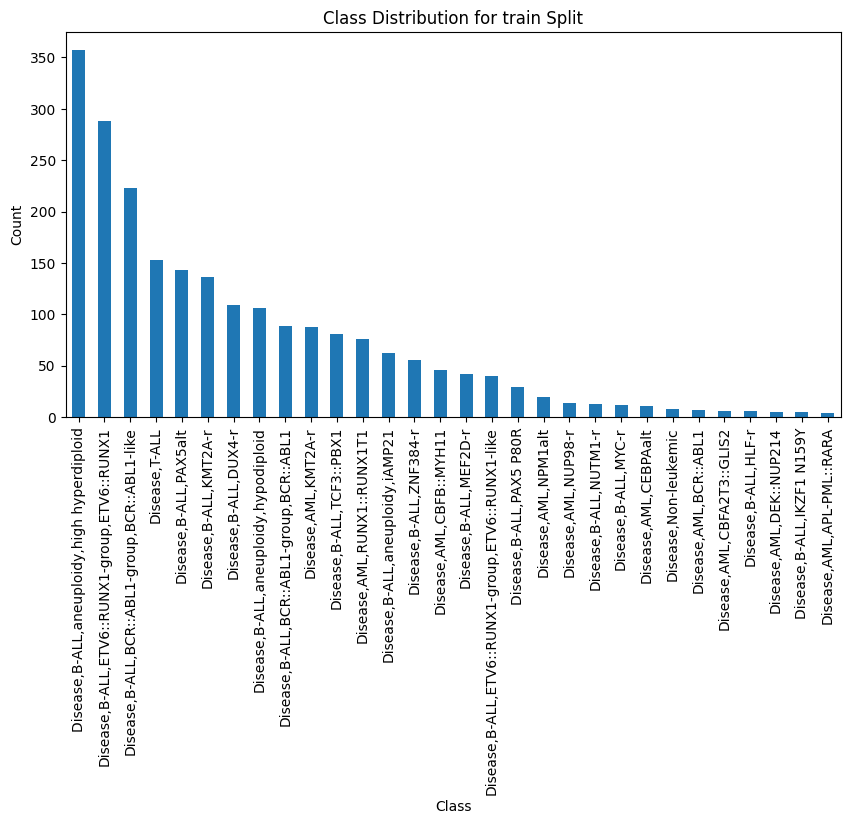

In [45]:
save_data_split(X_train, y_train, "train")


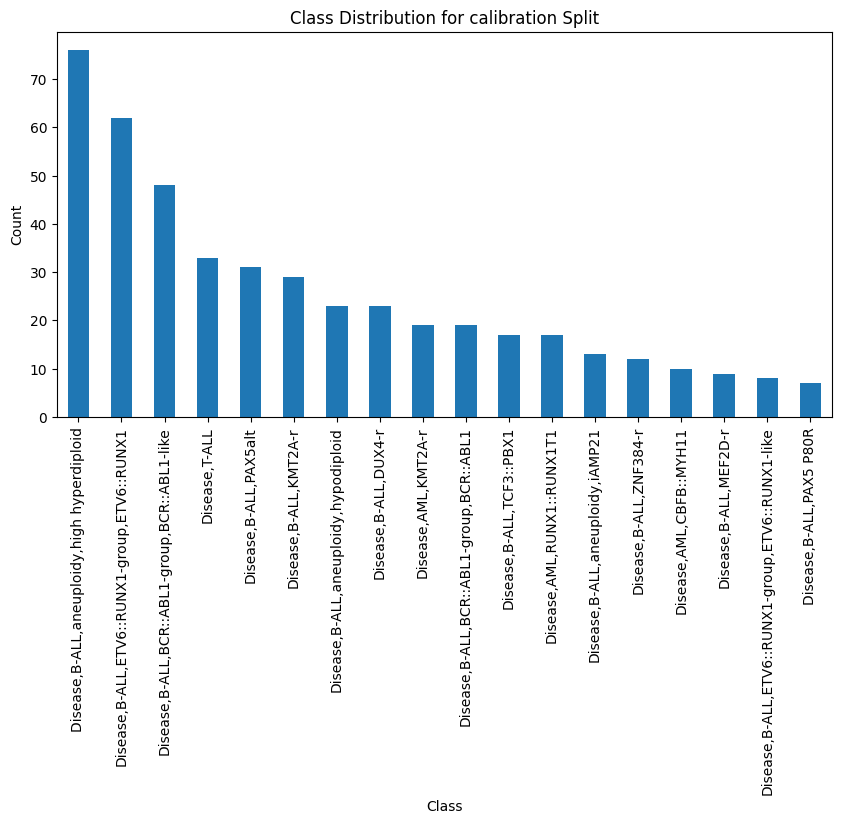

In [46]:
save_data_split(X_calib, y_calib, "calibration")


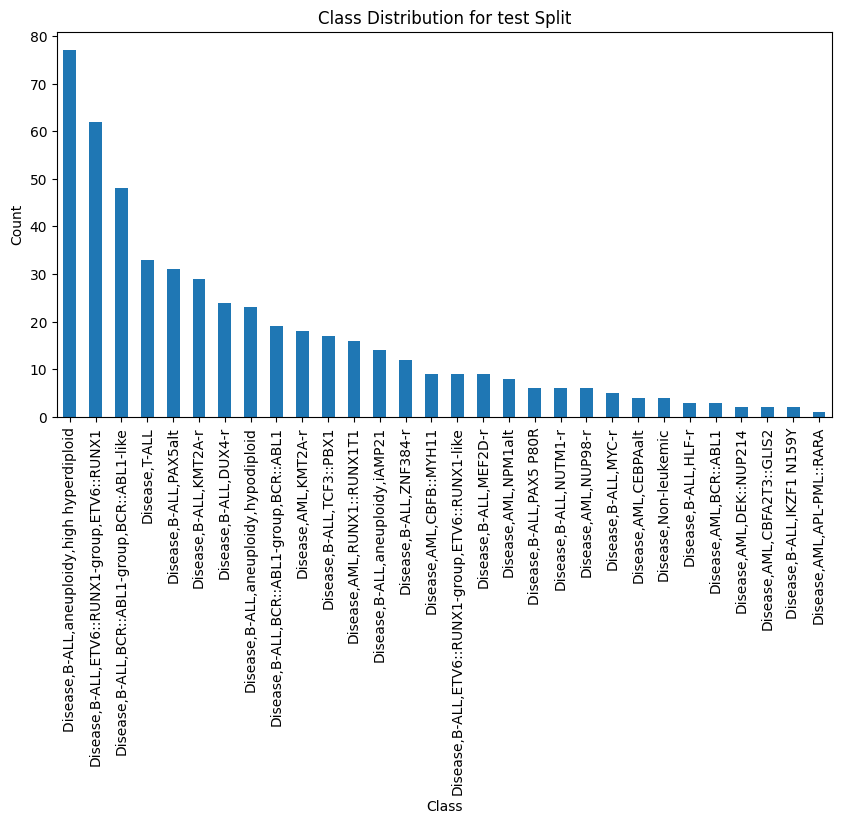

In [47]:
save_data_split(X_test, y_test, "test")


In [48]:
# Print final counts in all sets
print("\nFinal dataset sizes:")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Calibration set: {X_calib.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")


Final dataset sizes:
Training set: 2233 samples
Calibration set: 456 samples
Test set: 502 samples
